# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [ ]:
from pathlib import Path

DIR_PROC = Path("..") / "data" / "processed"

import pandas as pd
import matplotlib.pyplot as plt

## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [217]:
df = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["datetime"])

print("formato:", df.shape)
print("nulos no total:", df.isna().sum().sum())
print("intervalo:", df["datetime"].min(), "até", df["datetime"].max())
df.info()
df.head()

formato: (168, 13)
nulos no total: 0
intervalo: 2026-10-11 00:00:00 até 2026-10-17 23:00:00
<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              168 non-null    datetime64[us]
 1   hora_dia              168 non-null    int64         
 2   periodo               168 non-null    str           
 3   dia_semana            168 non-null    int64         
 4   fim_de_semana         168 non-null    bool          
 5   e_dia                 168 non-null    bool          
 6   coeficiente           168 non-null    int64         
 7   altura_mare_m         168 non-null    float64       
 8   sentido               168 non-null    str           
 9   altura_onda_m         168 non-null    float64       
 10  direcao_onda          168 non-null    str           
 11  velocidade_vento_kmh  168 non-null    float64       
 1

,datetime,hora_dia,periodo,dia_semana,fim_de_semana,e_dia,coeficiente,altura_mare_m,sentido,altura_onda_m,direcao_onda,velocidade_vento_kmh,direcao_vento
0,2026-10-11 00:00:00,0,madrugada,6,True,False,92,0.94,subindo,1.0,ESE,21.0,SE
1,2026-10-11 01:00:00,1,madrugada,6,True,False,92,1.28,subindo,1.0,ESE,22.0,SE
2,2026-10-11 02:00:00,2,madrugada,6,True,False,92,1.61,subindo,1.0,ESE,20.0,SE
3,2026-10-11 03:00:00,3,madrugada,6,True,False,92,1.94,subindo,1.0,ESE,17.0,ESE
4,2026-10-11 04:00:00,4,madrugada,6,True,False,92,2.27,subindo,1.0,ESE,21.0,ESE


**Conclusões da seção 1**

O `dataset.csv` carregou com 168 linhas e 13 colunas, sem nulos, cobrindo de 11/out 00:00 a 17/out 23:00 de 2026, como esperado da Etapa 2. Os tipos vieram como previstos: `datetime` como data; `fim_de_semana` e `e_dia` como booleanos; `hora_dia`, `dia_semana` e `coeficiente` como inteiros; `altura_mare_m`, `altura_onda_m` e `velocidade_vento_kmh` como `float64`; e `periodo`, `sentido`, `direcao_onda` e `direcao_vento` como texto (categorias).

## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

**Regra da label**

A label classifica cada **hora de luz** (`e_dia` verdadeiro, 91 das 168 horas) em **ruim**, **boa** ou **ótima**. As horas de noite ficam fora do modelo, porque não são utilizáveis para surfar e fariam a classe "ruim" ser dominada por `e_dia`.

A regra usa só duas variáveis, **altura da onda** e **velocidade do vento**. Maré e direção do vento ficam de fora: a maré não mostrou relação com a onda na EDA, e a direção do vento praticamente não varia na janela (ENE, E, ESE e poucas horas de SE). As duas variáveis de fora entram como features na seção 3, e a importância que o modelo der a elas é um teste do que a regra deixou de captar.

Premissa: **onda maior e vento mais fraco são melhores**. Cada variável dá de 0 a 2 pontos, e a soma (0 a 4) define a classe:

| Variável | Pontos | Corte | Horas |
|---|---|---|---|
| Onda | 2 / 1 / 0 | ≥ 1,4 m / 1,2 a 1,3 m / ≤ 1,1 m | 13 / 64 / 14 |
| Vento | 2 / 1 / 0 | ≤ 20 / 21 a 23 / ≥ 24 km/h | 40 / 39 / 12 |

Soma de 0 a 2: **ruim**; 3: **boa**; 4: **ótima**.

**Origem dos cortes:** a distribuição dos próprios dados. Os da onda separam o valor máximo da janela e a cauda baixa. Os do vento são os terços da distribuição. **Não vêm de uma fonte externa**, então são um chute informado, e as classes são **relativas a esta semana**: "ótima" quer dizer "entre as melhores horas desta janela", e não que o surfe seja excelente.

**Distribuição das classes:** ruim 50 (55%), boa 32 (35%), ótima 9 (10%). A classe "ótima" é pequena, e todas as suas horas estão em 14 e 15/10, o que afeta a divisão treino/teste e torna a acurácia pouco informativa.

Na modelagem, "boa" e "ótima" foram juntadas numa só classe (ver seção 4).

In [218]:
luz = df[df["e_dia"]].copy()
print(len(luz), "horas de luz\n")

print("Onda (m), número de horas por valor:")
print(luz["altura_onda_m"].value_counts().sort_index())

print("\nVento (km/h):")
print(luz["velocidade_vento_kmh"].describe())

print("\nOnda por dia (horas de luz):")
print(luz.groupby(luz["datetime"].dt.date)["altura_onda_m"].agg(["min", "mean", "max"]).round(2))

print("\nOnda x vento (vento em 3 faixas de mesmo tamanho):")
print(pd.crosstab(luz["altura_onda_m"], pd.qcut(luz["velocidade_vento_kmh"], 3, duplicates="drop")))

91 horas de luz

Onda (m), número de horas por valor:
altura_onda_m
0.9     1
1.0    12
1.1     1
1.2    35
1.3    29
1.4    13
Name: count, dtype: int64

Vento (km/h):
count    91.000000
mean     21.186813
std       2.699432
min      13.000000
25%      19.000000
50%      21.000000
75%      23.000000
max      28.000000
Name: velocidade_vento_kmh, dtype: float64

Onda por dia (horas de luz):
            min  mean  max
datetime                  
2026-10-11  0.9  0.99  1.0
2026-10-12  1.2  1.22  1.3
2026-10-13  1.2  1.23  1.3
2026-10-14  1.3  1.37  1.4
2026-10-15  1.3  1.33  1.4
2026-10-16  1.2  1.27  1.3
2026-10-17  1.1  1.19  1.2

Onda x vento (vento em 3 faixas de mesmo tamanho):
velocidade_vento_kmh  (12.999, 20.0]  (20.0, 23.0]  (23.0, 28.0]
altura_onda_m                                                   
0.9                                0             0             1
1.0                                2             4             6
1.1                                1             0 

In [219]:
def pontos_onda(h):
    if h >= 1.4:
        return 2
    if h >= 1.2:
        return 1
    return 0


def pontos_vento(v):
    if v <= 20:
        return 2
    if v <= 23:
        return 1
    return 0


luz["pontos_onda"] = luz["altura_onda_m"].apply(pontos_onda)
luz["pontos_vento"] = luz["velocidade_vento_kmh"].apply(pontos_vento)
luz["pontos"] = luz["pontos_onda"] + luz["pontos_vento"]
luz["label"] = luz["pontos"].map(
    lambda p: "ruim" if p <= 2 else ("boa" if p == 3 else "ótima")
)

print(luz["pontos"].value_counts().sort_index())
print()
print(luz["label"].value_counts())
print(luz["label"].value_counts(normalize=True).round(2))
print()
print(pd.crosstab(luz["datetime"].dt.date, luz["label"]))

pontos
0     7
1     9
2    34
3    32
4     9
Name: count, dtype: int64

label
ruim     50
boa      32
ótima     9
Name: count, dtype: int64
label
ruim     0.55
boa      0.35
ótima    0.10
Name: proportion, dtype: float64

label       boa  ruim  ótima
datetime                    
2026-10-11    0    13      0
2026-10-12    3    10      0
2026-10-13    3    10      0
2026-10-14    1     4      8
2026-10-15   12     0      1
2026-10-16    5     8      0
2026-10-17    8     5      0


## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

In [220]:
y = luz["label"]
dias = luz["datetime"].dt.date 

categoricas = ["sentido", "direcao_onda", "direcao_vento"]
base = ["hora_dia", "altura_mare_m"] + categoricas
da_regra = ["altura_onda_m", "velocidade_vento_kmh"]

X_sem_regra = pd.get_dummies(luz[base], columns=categoricas, dtype=int)
X_completo = pd.get_dummies(luz[base + da_regra], columns=categoricas, dtype=int)

print("X_sem_regra:", X_sem_regra.shape)
print("X_completo:", X_completo.shape)
print(list(X_completo.columns))
print()
print(y.value_counts())

X_sem_regra: (91, 10)
X_completo: (91, 12)
['hora_dia', 'altura_mare_m', 'altura_onda_m', 'velocidade_vento_kmh', 'sentido_descendo', 'sentido_subindo', 'direcao_onda_E', 'direcao_onda_ESE', 'direcao_vento_E', 'direcao_vento_ENE', 'direcao_vento_ESE', 'direcao_vento_SE']

label
ruim     50
boa      32
ótima     9
Name: count, dtype: int64


**Features e alvo**

- **Alvo (`y`):** a label (ruim, boa ou ótima; a seção 4 junta 'boa' e 'ótima', e o modelo trabalha com duas classes), definida na seção 2, nas 91 horas de luz.
- **Duas versões de features**, para separar o que o modelo reaprende da regra do que ele consegue prever por outras vias:
  - `X_completo`: hora do dia, altura da maré, sentido da maré, direção da onda, direção do vento, **altura da onda e velocidade do vento**. Como as duas últimas são as variáveis da regra, o modelo apenas redescobre o `if` que escrevi.
  - `X_sem_regra`: as mesmas, **sem** a altura da onda e a velocidade do vento. Aqui o modelo precisa prever a label com maré, hora e direções.
- **Fora das duas:** `pontos`, `pontos_onda` e `pontos_vento` (são a própria label); `coeficiente`, `dia_semana` e `fim_de_semana` (constantes dentro do dia, então com 7 dias funcionam como identificadores do dia); `periodo` (repete `hora_dia`); `e_dia` (sempre verdadeiro nas horas de luz).
- **Variáveis de texto** (`sentido`, `direcao_onda`, `direcao_vento`): transformadas com one-hot, uma coluna 0/1 por categoria, para não inventar uma ordem entre elas.

## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

In [221]:
y = y.replace({"ótima": "boa"}) 

In [222]:
dias_teste = ["2026-10-12", "2026-10-15", "2026-10-17"]
e_teste = dias.astype(str).isin(dias_teste)

X_tr_c, X_te_c = X_completo[~e_teste], X_completo[e_teste]
X_tr_s, X_te_s = X_sem_regra[~e_teste], X_sem_regra[e_teste]
y_tr, y_te = y[~e_teste], y[e_teste]

print("treino:", len(y_tr), "| teste:", len(y_te))
print(pd.DataFrame({"treino": y_tr.value_counts(), "teste": y_te.value_counts()}).fillna(0).astype(int))
print("\nDias no treino:", sorted(set(dias[~e_teste].astype(str))))
print("Dias no teste: ", sorted(set(dias[e_teste].astype(str))))

treino: 52 | teste: 39
       treino  teste
label               
boa        17     24
ruim       35     15

Dias no treino: ['2026-10-11', '2026-10-13', '2026-10-14', '2026-10-16']
Dias no teste:  ['2026-10-12', '2026-10-15', '2026-10-17']


**Divisão treino/teste**

Dividi **por dia inteiro**, e não sorteando linhas. As horas de um mesmo dia são muito parecidas entre si, então sortear linhas colocaria no teste "gêmeas" de horas vistas no treino e inflaria a nota. Por isso também não estratifiquei por classe: isso exigiria misturar horas do mesmo dia.

**Classes:** como a "ótima" só existe em 14/10 (8 horas) e 15/10 (1 hora), ela ficaria com um único exemplo no teste, e a sua métrica não seria confiável. Juntei "boa" e "ótima" numa só, então o problema passou a ter duas classes: **ruim** (0 a 2 pontos) e **boa** (3 ou 4 pontos). Essa decisão foi tomada antes de ver o desempenho dos modelos.

- **Treino:** 11, 13, 14 e 16/10 (52 horas): ruim 35, boa 17.
- **Teste:** 12, 15 e 17/10 (39 horas): ruim 15, boa 24.

A divisão por dia deixa as proporções diferentes: boa é 33% do treino e 62% do teste. Isso afeta a leitura das métricas, e os dias de teste foram escolhidos de forma arbitrária. Por isso, na seção 6, a avaliação vai ser complementada por validação cruzada deixando um dia de fora por vez.

## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [223]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

treinos = {"completo": X_tr_c, "sem_regra": X_tr_s}

modelos = {}
for nome_x, X_tr in treinos.items():
    modelos[("arvore", nome_x)] = DecisionTreeClassifier(
        max_depth=3, random_state=42
    ).fit(X_tr, y_tr)
    modelos[("knn", nome_x)] = make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ).fit(X_tr, y_tr)

baseline = DummyClassifier(strategy="most_frequent").fit(X_tr_c, y_tr)

print("modelos treinados:")
for modelo, nome_x in modelos:
    print(f"- {modelo} ({nome_x})")

modelos treinados:
- arvore (completo)
- knn (completo)
- arvore (sem_regra)
- knn (sem_regra)


**Modelos**

Treinei dois modelos de famílias diferentes, cada um nas duas versões de features (`X_completo` e `X_sem_regra`):

- **Árvore de decisão** (`max_depth=3`): interpretável, e é a que vou plotar na seção 7. Limitei a profundidade porque, com 52 linhas de treino, uma árvore livre decoraria os dados.
- **KNN** (`n_neighbors=5`), com `StandardScaler` antes: é baseado em distância, e as colunas têm escalas muito diferentes (hora de 0 a 23, maré de cerca de 0 a 2,5 m, vento de 13 a 28 km/h), que dominariam a distância sem escalonar.
- **Baseline:** um classificador que sempre prevê a classe mais frequente do treino (ruim), como piso de comparação.

Os hiperparâmetros foram escolhidos sem olhar o teste e não foram ajustados, porque com tão poucos dados qualquer ajuste ficaria contaminado.

## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

     modelo   features  acuracia  acuracia_balanceada  f1_boa
0    arvore   completo      1.00                  1.0    1.00
1       knn   completo      0.64                  0.7    0.61
2    arvore  sem_regra      0.77                  0.8    0.78
3       knn  sem_regra      0.54                  0.6    0.47
4  baseline          -      0.38                  0.5    0.00


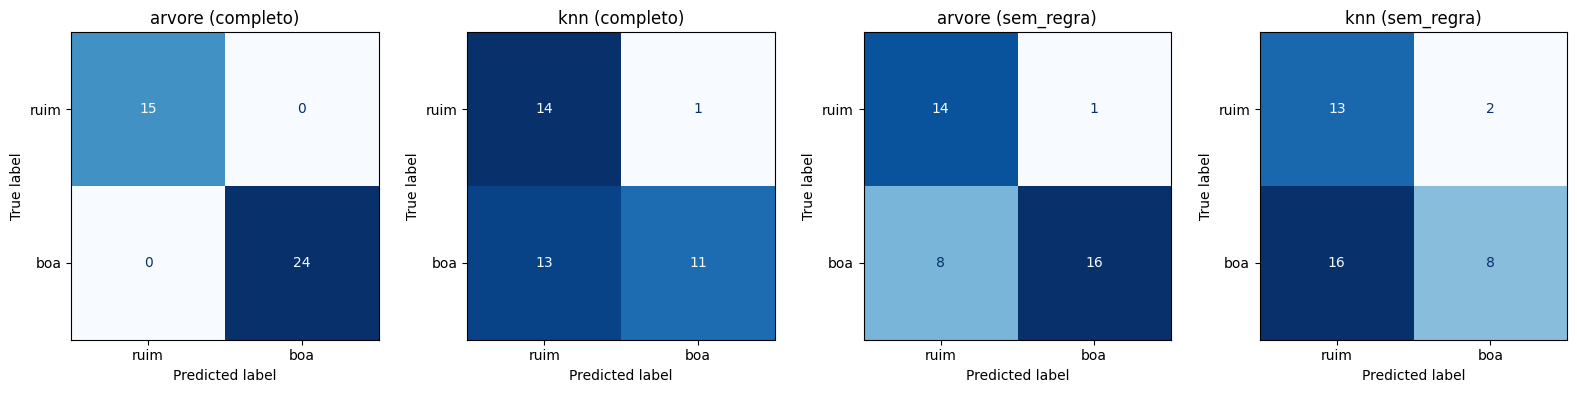

In [224]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, ConfusionMatrixDisplay,
)

testes = {"completo": X_te_c, "sem_regra": X_te_s}
rotulos = ["ruim", "boa"]

linhas, previsoes = [], {}
for (modelo, nome_x), m in modelos.items():
    pred = m.predict(testes[nome_x])
    previsoes[(modelo, nome_x)] = pred
    linhas.append({
        "modelo": modelo, "features": nome_x,
        "acuracia": accuracy_score(y_te, pred),
        "acuracia_balanceada": balanced_accuracy_score(y_te, pred),
        "f1_boa": f1_score(y_te, pred, pos_label="boa", zero_division=0),
    })

pred_base = baseline.predict(X_te_c)
linhas.append({
    "modelo": "baseline", "features": "-",
    "acuracia": accuracy_score(y_te, pred_base),
    "acuracia_balanceada": balanced_accuracy_score(y_te, pred_base),
    "f1_boa": f1_score(y_te, pred_base, pos_label="boa", zero_division=0),
})
print(pd.DataFrame(linhas).round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, ((modelo, nome_x), pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_te, pred, labels=rotulos, ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(f"{modelo} ({nome_x})")
plt.tight_layout()
plt.show()

In [225]:
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score

grupos = dias.astype(str).values
dados = {"completo": X_completo, "sem_regra": X_sem_regra}

resultado = {}
for (modelo, nome_x), m in modelos.items():
    resultado[f"{modelo} ({nome_x})"] = cross_val_score(
        clone(m), dados[nome_x], y, groups=grupos,
        cv=LeaveOneGroupOut(), scoring="accuracy",
    )
resultado["baseline"] = cross_val_score(
    clone(baseline), X_completo, y, groups=grupos,
    cv=LeaveOneGroupOut(), scoring="accuracy",
)

por_dia = pd.DataFrame(resultado, index=sorted(set(grupos))).round(2)
print(por_dia)
print("\nmédia:")
print(por_dia.mean().round(2))

            arvore (completo)  knn (completo)  arvore (sem_regra)  \
2026-10-11                1.0            0.92                0.85   
2026-10-12                1.0            0.92                0.92   
2026-10-13                1.0            0.77                0.77   
2026-10-14                1.0            0.62                0.62   
2026-10-15                1.0            0.69                0.38   
2026-10-16                1.0            0.38                0.77   
2026-10-17                1.0            0.54                0.85   

            knn (sem_regra)  baseline  
2026-10-11             0.92      0.00  
2026-10-12             0.85      0.77  
2026-10-13             0.69      0.77  
2026-10-14             0.62      0.31  
2026-10-15             0.54      0.00  
2026-10-16             0.38      0.62  
2026-10-17             0.54      0.38  

média:
arvore (completo)     1.00
knn (completo)        0.69
arvore (sem_regra)    0.74
knn (sem_regra)       0.65
baseline   

**Avaliação**

| Modelo | Features | Acurácia (teste) | Acurácia balanceada | F1 "boa" | Acurácia média (validação por dia) |
|---|---|---|---|---|---|
| Árvore | completo | 1,00 | 1,00 | 1,00 | 1,00 |
| KNN | completo | 0,64 | 0,70 | 0,61 | 0,69 |
| Árvore | sem_regra | 0,77 | 0,80 | 0,78 | 0,74 |
| KNN | sem_regra | 0,54 | 0,60 | 0,47 | 0,65 |
| Baseline | - | 0,38 | 0,50 | 0,00 | 0,41 |

**A acurácia basta?** Não. As classes estão desbalanceadas e mudam entre treino (33% boa) e teste (62% boa), então a acurácia sozinha engana: o baseline marca 0,38 no teste, mas na validação cruzada ele prevê a classe majoritária do treino de cada volta, que se inverte conforme o dia deixado de fora, e a média cai para 0,41. Por isso olhei também a acurácia balanceada (a média da taxa de acerto por classe) e o F1 da classe "boa".

**Que erro os modelos cometem?** Os modelos que não reproduzem a regra erram quase sempre no mesmo sentido: classificam horas "boa" como "ruim". A árvore (sem_regra) perde 8 das 24 horas boas e marca 1 hora ruim como boa; o KNN (completo) perde 13 e erra 1; o KNN (sem_regra) perde 16 e erra 2. São conservadores: raramente apontam como boa uma hora ruim, mas deixam passar muitas horas boas.

**Um único split é confiável?** Não. Com 39 horas de teste em 3 dias, a árvore (sem_regra) acerta 77%, mas na validação cruzada deixando um dia de fora ela vai de 38% (15/10) a 92% (12/10). Cada dia tem 13 horas, então uma hora vale cerca de 8 pontos percentuais. A média por dia é mais confiável, mas são só 7 dias, e dias vizinhos são parecidos entre si.

**Leitura:**
- A árvore com as variáveis da regra acerta 100% em todos os dias porque redescobre o `if` da seção 2. Isso não mede previsão do mar (seção 7).
- Sem as variáveis da regra, a árvore (0,74) e o KNN (0,65) ficam acima do baseline (0,41) na média. A árvore empata ou supera o baseline em todos os dias; o KNN (sem_regra) fica abaixo dele em 13/10 e 16/10. A seção 7 mostra que essa árvore usa sobretudo a hora do dia (0,42) e a direção do vento (ESE 0,31 e E 0,09).

## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

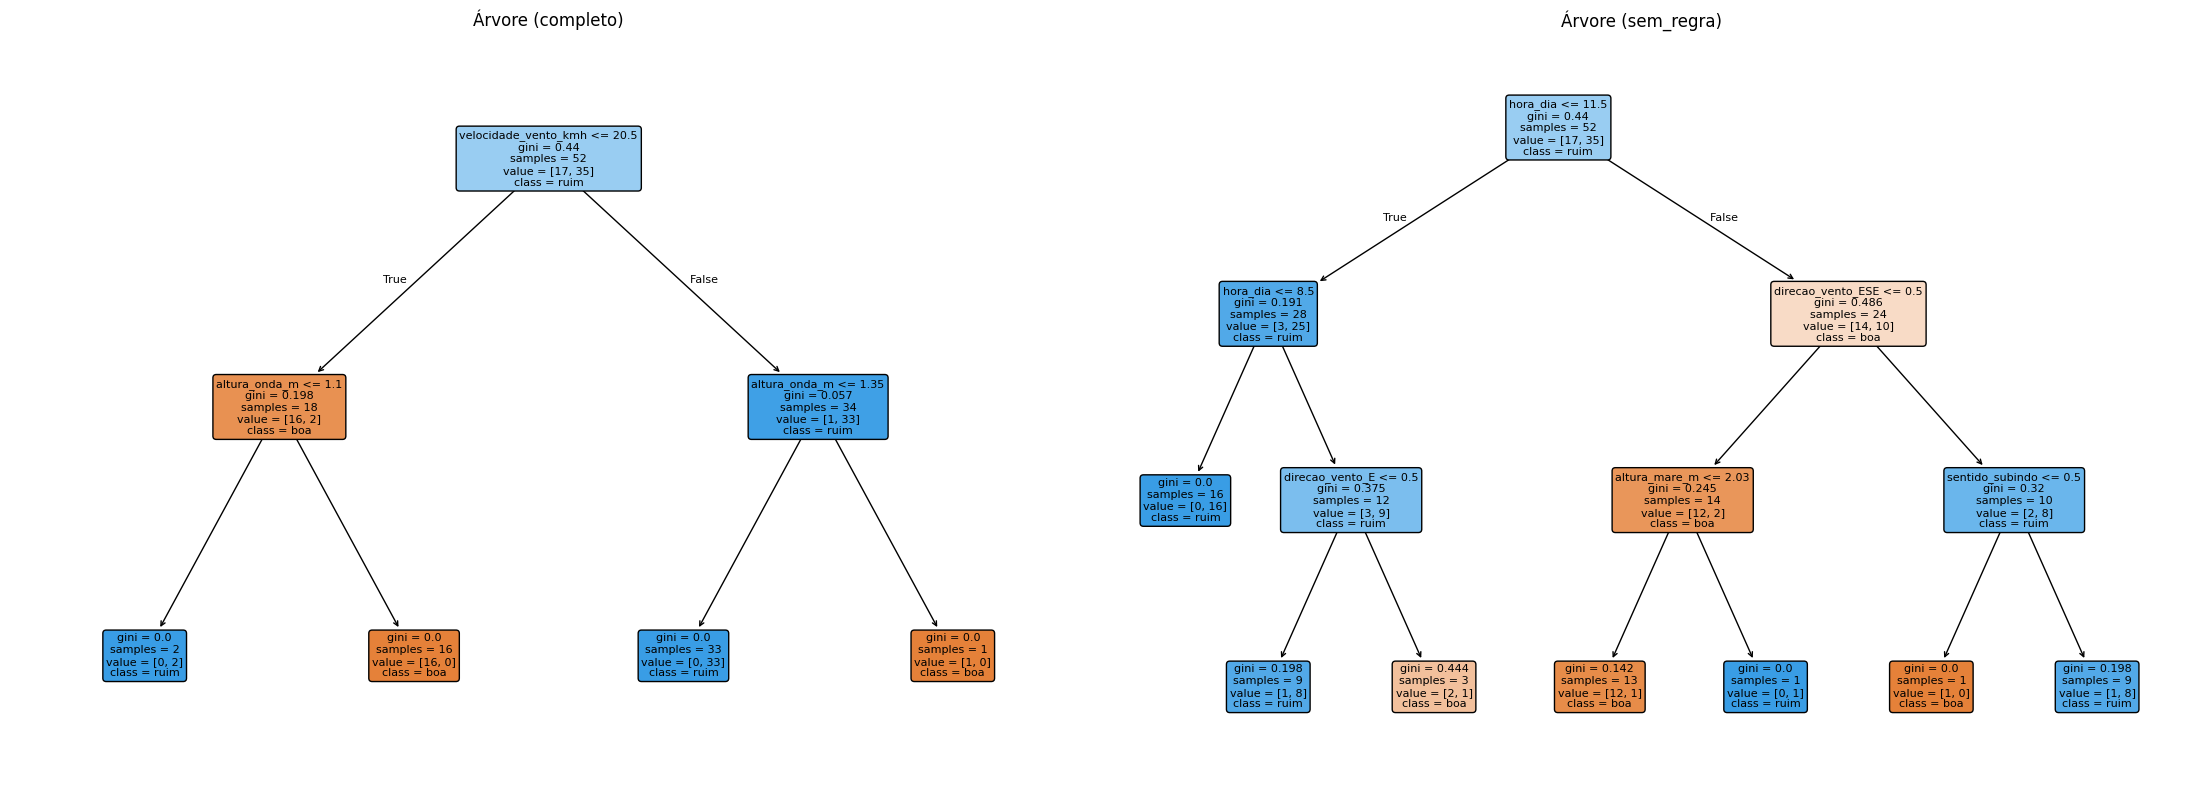

                      completo  sem_regra
velocidade_vento_kmh      0.76       0.00
altura_onda_m             0.24       0.00
direcao_onda_E            0.00       0.00
altura_mare_m             0.00       0.10
direcao_onda_ESE          0.00       0.00
direcao_vento_E           0.00       0.09
direcao_vento_ESE         0.00       0.31
direcao_vento_ENE         0.00       0.00
direcao_vento_SE          0.00       0.00
hora_dia                  0.00       0.42
sentido_descendo          0.00       0.00
sentido_subindo           0.00       0.09


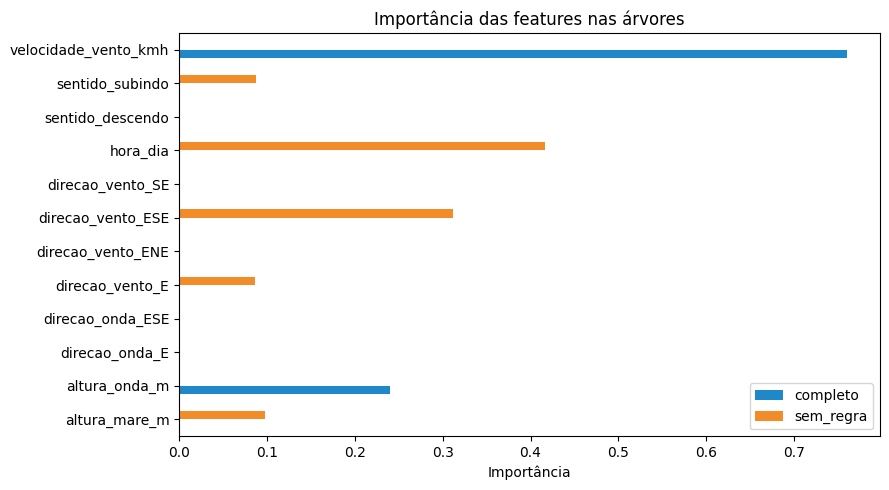

In [226]:
from sklearn.tree import plot_tree

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, nome_x, X_tr in zip(axes, ["completo", "sem_regra"], [X_tr_c, X_tr_s]):
    arvore = modelos[("arvore", nome_x)]
    plot_tree(
        arvore, feature_names=list(X_tr.columns),
        class_names=list(arvore.classes_),
        filled=True, rounded=True, fontsize=8, ax=ax,
    )
    ax.set_title(f"Árvore ({nome_x})")
plt.tight_layout()
plt.show()

imp = pd.DataFrame({
    "completo": pd.Series(modelos[("arvore", "completo")].feature_importances_, index=X_tr_c.columns),
    "sem_regra": pd.Series(modelos[("arvore", "sem_regra")].feature_importances_, index=X_tr_s.columns),
}).fillna(0)
print(imp.round(2).sort_values("completo", ascending=False))

imp.plot.barh(figsize=(9, 5), color=["#1E88C8", "#F28C28"])
plt.title("Importância das features nas árvores")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

**Interpretação**

**Árvore (completo).** Corta primeiro a velocidade do vento (≤ 20,5 km/h) e depois a altura da onda (≤ 1,1 m com vento fraco; ≤ 1,35 m com vento mais forte). Isso reproduz a regra da seção 2: com vento até 20 km/h, onda de 1,2 m ou mais dá "boa"; com vento maior, só a onda de 1,4 m. Os cortes caem no ponto médio entre os valores vizinhos dos meus limiares. Não há corte em 23/24 km/h porque, na janela, nunca há onda de 1,4 m com vento de 24 km/h ou mais, o único caso em que esse limiar faria diferença. As importâncias são vento 0,76 e onda 0,24, e todas as outras features valem zero.

**A acurácia de 1,00 não é previsão do mar.** A label é uma função exata da altura da onda e da velocidade do vento, e essas duas colunas estão nas features do modelo `completo`, então a árvore apenas redescobriu o `if` da seção 2. Isso vale para os 7 dias da validação cruzada.

**Árvore (sem_regra).** Usa principalmente a hora do dia (importância 0,42), com cortes em 8,5 h e 11,5 h: de madrugada e de manhã quase tudo é "ruim", e à tarde predomina "boa", exceto quando o vento é de ESE (0,31). Isso combina com a EDA, que mostrou vento mais forte de madrugada e mais fraco à tarde, e sugere que a hora do dia funciona como substituta do padrão do vento, variável da regra. A direção do vento também é informação de vento, então esta versão não é uma prova de que maré e hora, sozinhas, expliquem a label.

**A maré tem peso pequeno** (altura 0,10; sentido 0,09), e só em folhas minúsculas: cada corte isola 1 hora das 14 ou das 10 que sobram, o que é pouca evidência com 52 linhas de treino. Isso é compatível com a EDA, que não encontrou relação entre maré e onda.

**Em que grau é previsão do mar?** Sem as variáveis da regra, a árvore chega a 0,74 de acurácia média, contra 0,41 do baseline, mas apoiada na hora do dia e na direção do vento, que são substitutos do padrão do vento. Provavelmente por não enxergar a altura da onda (que varia sobretudo entre dias), ela perde muitas horas "boas" (seção 6). Nenhuma variável independente do mar (a maré, por exemplo) sustenta a previsão de forma clara.

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

       boa_regra  p_boa_completo  p_boa_sem_regra
dia                                              
11/10       0.00            0.00             0.05
12/10       0.23            0.23             0.26
13/10       0.23            0.23             0.26
14/10       0.69            0.69             0.68
15/10       1.00            1.00             0.71
16/10       0.38            0.38             0.59
17/10       0.62            0.62             0.61 

          boa_regra  p_boa_completo  p_boa_sem_regra
hora_dia                                            
5              0.14            0.14             0.17
6              0.14            0.14             0.21
7              0.14            0.14             0.17
8              0.29            0.29             0.22
9              0.29            0.29             0.17
10             0.43            0.43             0.52
11             0.43            0.43             0.56
12             0.43            0.43             0.61
13             0.7

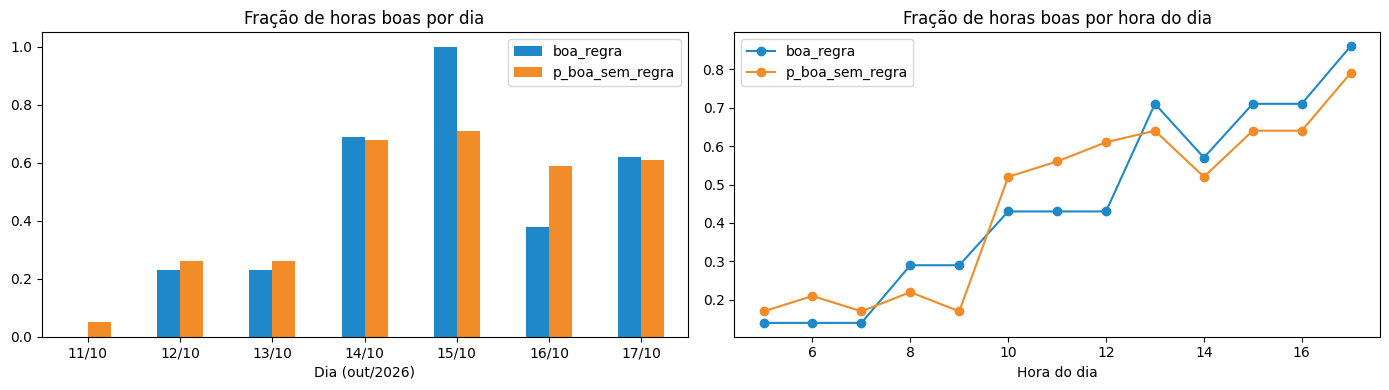

In [227]:
from sklearn.base import clone

completo = clone(modelos[("arvore", "completo")]).fit(X_completo, y)
sem_regra = clone(modelos[("arvore", "sem_regra")]).fit(X_sem_regra, y)

res = luz[["datetime", "hora_dia", "altura_onda_m", "velocidade_vento_kmh"]].copy()
res["dia"] = res["datetime"].dt.strftime("%d/%m")
res["boa_regra"] = (y == "boa").astype(int)
res["p_boa_completo"] = completo.predict_proba(X_completo)[:, list(completo.classes_).index("boa")]
res["p_boa_sem_regra"] = sem_regra.predict_proba(X_sem_regra)[:, list(sem_regra.classes_).index("boa")]

colunas = ["boa_regra", "p_boa_completo", "p_boa_sem_regra"]
por_dia = res.groupby("dia")[colunas].mean().round(2)
por_hora = res.groupby("hora_dia")[colunas].mean().round(2)
print(por_dia, "\n")
print(por_hora, "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_dia[["boa_regra", "p_boa_sem_regra"]].plot.bar(ax=axes[0], color=["#1E88C8", "#F28C28"], rot=0)
axes[0].set_title("Fração de horas boas por dia")
axes[0].set_xlabel("Dia (out/2026)")
por_hora[["boa_regra", "p_boa_sem_regra"]].plot(ax=axes[1], color=["#1E88C8", "#F28C28"], marker="o")
axes[1].set_title("Fração de horas boas por hora do dia")
axes[1].set_xlabel("Hora do dia")
plt.tight_layout()
plt.show()

In [228]:
rank = luz[["datetime", "altura_onda_m", "velocidade_vento_kmh", "pontos"]].sort_values(
    ["pontos", "altura_onda_m", "velocidade_vento_kmh"],
    ascending=[False, False, True],
)
print(rank.head(10).to_string(index=False))
print()
print(rank["pontos"].value_counts().sort_index(ascending=False))

           datetime  altura_onda_m  velocidade_vento_kmh  pontos
2026-10-14 09:00:00            1.4                  18.0       4
2026-10-14 10:00:00            1.4                  18.0       4
2026-10-14 12:00:00            1.4                  18.0       4
2026-10-14 13:00:00            1.4                  18.0       4
2026-10-15 08:00:00            1.4                  18.0       4
2026-10-14 11:00:00            1.4                  19.0       4
2026-10-14 14:00:00            1.4                  19.0       4
2026-10-14 17:00:00            1.4                  19.0       4
2026-10-14 16:00:00            1.4                  20.0       4
2026-10-14 15:00:00            1.4                  21.0       3

pontos
4     9
3    32
2    34
1     9
0     7
Name: count, dtype: int64


**Resposta para Felipe e Nicholas**

Aplicando a regra (e as árvores) às 91 horas de luz da janela de 11 a 17/out/2026:

**Melhores dias.** Pela regra, 15/10 tem todas as 13 horas de luz classificadas como "boa" ou "ótima" (100%), seguido de 14/10 (69%, 9 de 13 horas, das quais 8 são "ótimas"), 17/10 (62%) e 16/10 (38%). Os dias 12 e 13/10 têm 23% de horas boas, e 11/10 nenhuma. Os dias 14 e 15/10 concentram também as ondas de 1,4 m, as maiores da janela.

**Melhor horário do dia.** Em média, a fração de horas boas aumenta ao longo do dia: 14% às 5h–7h (1 dos 7 dias), 43% às 10h–12h, 71% às 13h, 15h e 16h, e 86% às 17h (6 dos 7 dias), com uma queda isolada às 14h (57%). Como a onda varia por dia e quase não varia por hora, esse padrão provavelmente vem sobretudo do vento, que é mais fraco à tarde (não separei o efeito das duas variáveis). Ressalvas: cada hora tem só 7 observações (uma por dia), e as 17h são a última hora de luz (o pôr do sol é por volta das 17h15).

**Melhores horas da janela:** As 9 horas com pontuação máxima (4 pontos) são 8 de 14/10 (às 9h, 10h, 11h, 12h, 13h, 14h, 16h e 17h) e 1 de 15/10 (às 8h), todas com onda de 1,4 m e vento de 18 a 20 km/h. Às 15h de 14/10 a onda é igual, mas o vento de 21 km/h tira um ponto. Logo depois vêm as 32 horas de 3 pontos.

**Em que grau é previsão do mar e em que grau é a regra reescrita**
- A árvore (completo) dá exatamente os mesmos resultados da regra (`boa_regra` e `p_boa_completo` são idênticas), porque redescobre o `if` da seção 2. Os dias e horários acima são, portanto, **a regra reescrita**, e não um modelo que aprendeu algo sobre o mar.
- A árvore (sem_regra) acompanha a ordem geral dos dias (11/10 no fundo, 14 e 15/10 no topo), mas só porque a hora do dia e a direção do vento carregam parte da informação do vento, e erra os níveis: dá 0,71 para 15/10 (regra: 1,00) e 0,59 para 16/10 (regra: 0,38). Além disso, foi ajustada nas mesmas 91 horas em que é aplicada, então esses valores são otimistas.
- Os próprios dados de entrada são **previsões do site** (onda e vento) e uma tábua de marés, e não medições. A resposta é, no máximo, tão boa quanto essa previsão e quanto os limiares da regra, que vêm da distribuição da própria semana.

## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.

**1. Recomendação em uma frase**

Nesta semana (11 a 17/out), o dia com mais horas boas é 15/10 (todas as 13 horas de luz) e as 8 melhores horas são de 14/10, das 9h às 17h (exceto 15h), com onda de 1,4 m e vento de 18 a 20 km/h; à tarde há mais horas boas que de manhã cedo, mas isso vale só para esta semana e é a minha regra aplicada a 7 dias.

**2. O teto do modelo e o que melhoraria a regra**

O modelo reproduz a minha heurística: a árvore completa dá resultados idênticos aos da regra, então é tão boa quanto ela. Algumas ideias para melhorá-la:
- **Limiares de fonte externa** (um guia de surfe ou surfistas locais), em vez da distribuição da própria semana. Hoje "ótima" quer dizer "entre as melhores horas desta semana", e não que o surfe seja excelente.
- **Mais variáveis** que influenciam a onda e que o dataset não tem, como o período da onda e a direção do vento em relação à costa, que a regra não usa porque na janela a direção quase não varia.
- **Pesos diferentes** para onda e vento, em vez de pesos iguais por pontos.
- **Uma label independente da regra** (avaliações de surfistas para cada hora, por exemplo). Só assim o modelo poderia aprender algo sobre o mar, e não apenas reescrever o `if`.

**3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar**

- O dataset tem 168 linhas, 91 de luz, em 7 dias seguidos. Horas vizinhas são parecidas, então há bem menos de 91 observações independentes.
- Cada hora do dia tem só 7 observações, então os "melhores horários" são tendências desta semana, e não regras.
- A onda varia sobretudo entre dias, e com 7 dias não dá para separar o efeito do dia do efeito da maré ou da hora.
- A classe "ótima" só existe em 2 dias (9 horas), por isso juntei "boa" e "ótima", e o teste cobre só 3 dias (39 horas). As métricas variam muito conforme o dia (a árvore sem_regra vai de 38% a 92%).
- Onda e vento são previsões do site, e não medições; a altura da maré horária é uma interpolação da tábua.
- Os resultados não dizem nada sobre outras semanas, e muito menos sobre estações.

**4. Como responder "qual a melhor época do ano para surfar em João Pessoa"**

Faltam dados de onda e vento ao longo do ano: o site só oferece uma previsão de ~7 dias à frente. A tábua de marés de 2025 cobre o ano, mas é só a maré, e a maré não mostrou relação com a onda. Para responder, eu precisaria de:
- **Dados de onda e vento por mês**, de preferência observados (e não previsões) e de vários anos. Uma fonte de histórico precisaria ser procurada.
- **Como coletar com o que já tenho:** rodar o `scrape.py` todos os dias, de forma agendada, guardando a previsão de cada dia com a data de coleta, e acumular por 12 meses. Ainda assim seriam previsões feitas dia a dia, e não medições.
- Uma regra de label com fonte externa, para a comparação entre meses significar algo.